In [1]:
# =============================================================
# 08_evaluation.ipynb
# Tujuan : Generate semua tabel dan figur final untuk paper.
#          ROC curves, CRITICAL case study, complementarity
#          analysis, comparison table.
# Input  : Semua *_results.pkl
# Output : Paper-ready figures dan tables
# =============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import os
from datetime import datetime
from sklearn.metrics import roc_curve, auc, precision_recall_curve

from google.colab import drive
drive.mount("/content/drive")
DRIVE_DIR = "/content/drive/MyDrive/Tugas Pak Imam/Teknis 2/artifacts"

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 300, "font.size": 11,
    "axes.titlesize": 13, "axes.labelsize": 12,
    "xtick.labelsize": 10, "ytick.labelsize": 10,
    "legend.fontsize": 10, "figure.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3,
    "font.family": "serif",
})

print(f"Execution date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

# Load all results
with open(os.path.join(DRIVE_DIR, "mewma_results.pkl"), "rb") as f:
    mewma = pickle.load(f)
with open(os.path.join(DRIVE_DIR, "bilstm_results.pkl"), "rb") as f:
    bilstm = pickle.load(f)
with open(os.path.join(DRIVE_DIR, "fusion_results.pkl"), "rb") as f:
    fusion = pickle.load(f)
with open(os.path.join(DRIVE_DIR, "baseline_results.pkl"), "rb") as f:
    baseline = pickle.load(f)

print("All results loaded.")

# Gather test set scores and labels
scores = {
    "Isolation Forest": baseline["iso_test_rank"],
    "One-Class SVM": baseline["ocsvm_test_rank"],
    "MEWMA": mewma["t2_test_raw"],
    "BiLSTM-AE": np.concatenate([
        np.full(bilstm["best_window"] - 1, np.median(bilstm["recon_train"])),
        bilstm["recon_test"]
    ]),
    "Hybrid Fusion": baseline["iso_test_rank"],  # placeholder, recompute below
}

# Recompute rank-normalized and fusion for full-length test
from scipy.stats import rankdata

def rank_normalize(s):
    r = rankdata(s, method="average")
    return (r - 1) / (len(r) - 1)

mewma_test_rank = rank_normalize(mewma["t2_test_raw"])
bilstm_test_full = np.concatenate([
    np.full(bilstm["best_window"] - 1, np.median(bilstm["recon_train"])),
    bilstm["recon_test"]
])
bilstm_test_rank = rank_normalize(bilstm_test_full)
static_test_rank = 0.5 * mewma_test_rank + 0.5 * bilstm_test_rank

iso_test_rank = baseline["iso_test_rank"]
ocsvm_test_rank = baseline["ocsvm_test_rank"]

y_test_proxy = baseline["y_test_proxy"]
y_test_refined = baseline["y_test_refined"]
sev_test = baseline["sev_test"]

scores_rank = {
    "Isolation Forest": iso_test_rank,
    "One-Class SVM": ocsvm_test_rank,
    "MEWMA (Layer 1)": mewma_test_rank,
    "BiLSTM-AE (Layer 2)": bilstm_test_rank,
    "Hybrid Fusion (Ours)": static_test_rank,
}

print(f"Test set: {len(y_test_refined)} samples, "
      f"{y_test_refined.sum()} refined anomalies, "
      f"{(sev_test == 'CRITICAL').sum()} CRITICAL")

Mounted at /content/drive
Execution date: 2026-09-04 12:36:43
All results loaded.
Test set: 4368 samples, 477 refined anomalies, 4 CRITICAL


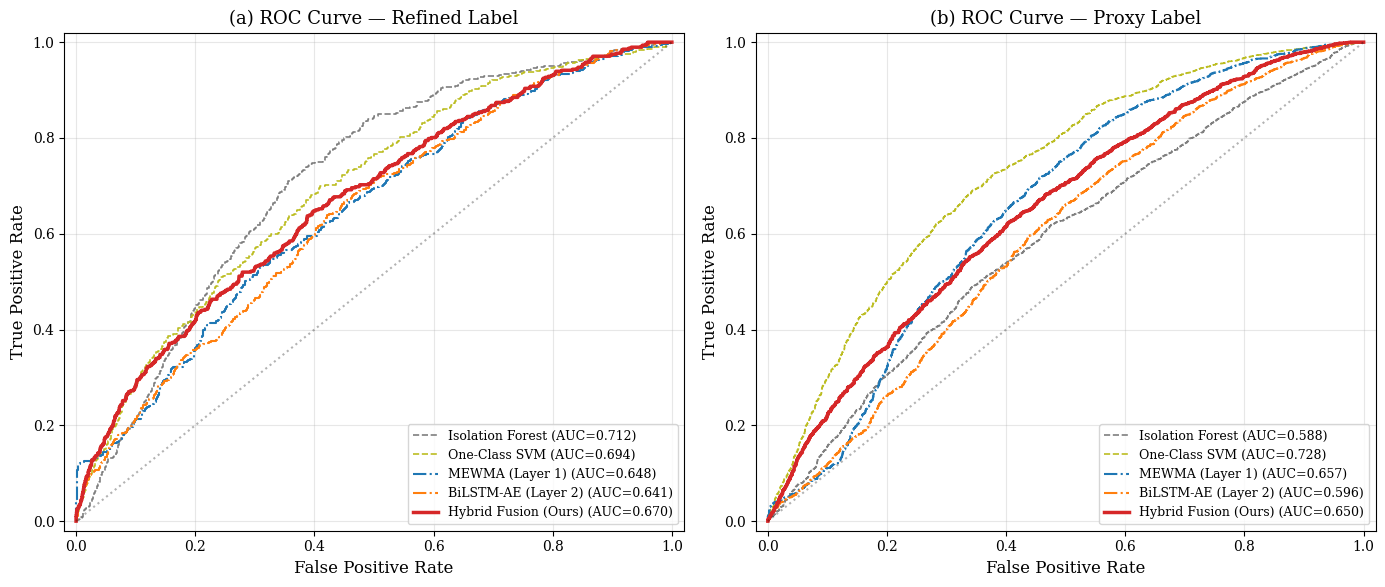

Saved: /content/drive/MyDrive/Tugas Pak Imam/Teknis 2/artifacts/fig07_roc_curves.png


In [2]:
# --- ROC Curves ---
# Tujuan : Figure utama paper — ROC curve semua metode pada refined label
# Input  : scores_rank, y_test_refined
# Output : fig07_roc_curves.png

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

colors = {
    "Isolation Forest": "#7f7f7f",
    "One-Class SVM": "#bcbd22",
    "MEWMA (Layer 1)": "#1f77b4",
    "BiLSTM-AE (Layer 2)": "#ff7f0e",
    "Hybrid Fusion (Ours)": "#d62728",
}
linestyles = {
    "Isolation Forest": "--",
    "One-Class SVM": "--",
    "MEWMA (Layer 1)": "-.",
    "BiLSTM-AE (Layer 2)": "-.",
    "Hybrid Fusion (Ours)": "-",
}
linewidths = {
    "Isolation Forest": 1.2,
    "One-Class SVM": 1.2,
    "MEWMA (Layer 1)": 1.5,
    "BiLSTM-AE (Layer 2)": 1.5,
    "Hybrid Fusion (Ours)": 2.5,
}

# Panel A: Refined label
ax = axes[0]
for name, s in scores_rank.items():
    fpr, tpr, _ = roc_curve(y_test_refined, s)
    auc_val = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc_val:.3f})",
            color=colors[name], linestyle=linestyles[name],
            linewidth=linewidths[name])

ax.plot([0, 1], [0, 1], "k:", alpha=0.3)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("(a) ROC Curve — Refined Label")
ax.legend(loc="lower right", fontsize=9)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])

# Panel B: Proxy label
ax = axes[1]
for name, s in scores_rank.items():
    fpr, tpr, _ = roc_curve(y_test_proxy, s)
    auc_val = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc_val:.3f})",
            color=colors[name], linestyle=linestyles[name],
            linewidth=linewidths[name])

ax.plot([0, 1], [0, 1], "k:", alpha=0.3)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("(b) ROC Curve — Proxy Label")
ax.legend(loc="lower right", fontsize=9)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])

plt.tight_layout()
fig_path = os.path.join(DRIVE_DIR, "fig07_roc_curves.png")
plt.savefig(fig_path, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

CRITICAL events in test set:
  CRIT 1: 2026-04-06T22:30:00.000000000 — PANIC-01
  CRIT 2: 2026-04-29T04:30:00.000000000 — WATER-LEAK-01
  CRIT 3: 2026-05-21T18:00:00.000000000 — FIRE-01
  CRIT 4: 2026-06-09T23:00:00.000000000 — WATER-LEAK-01


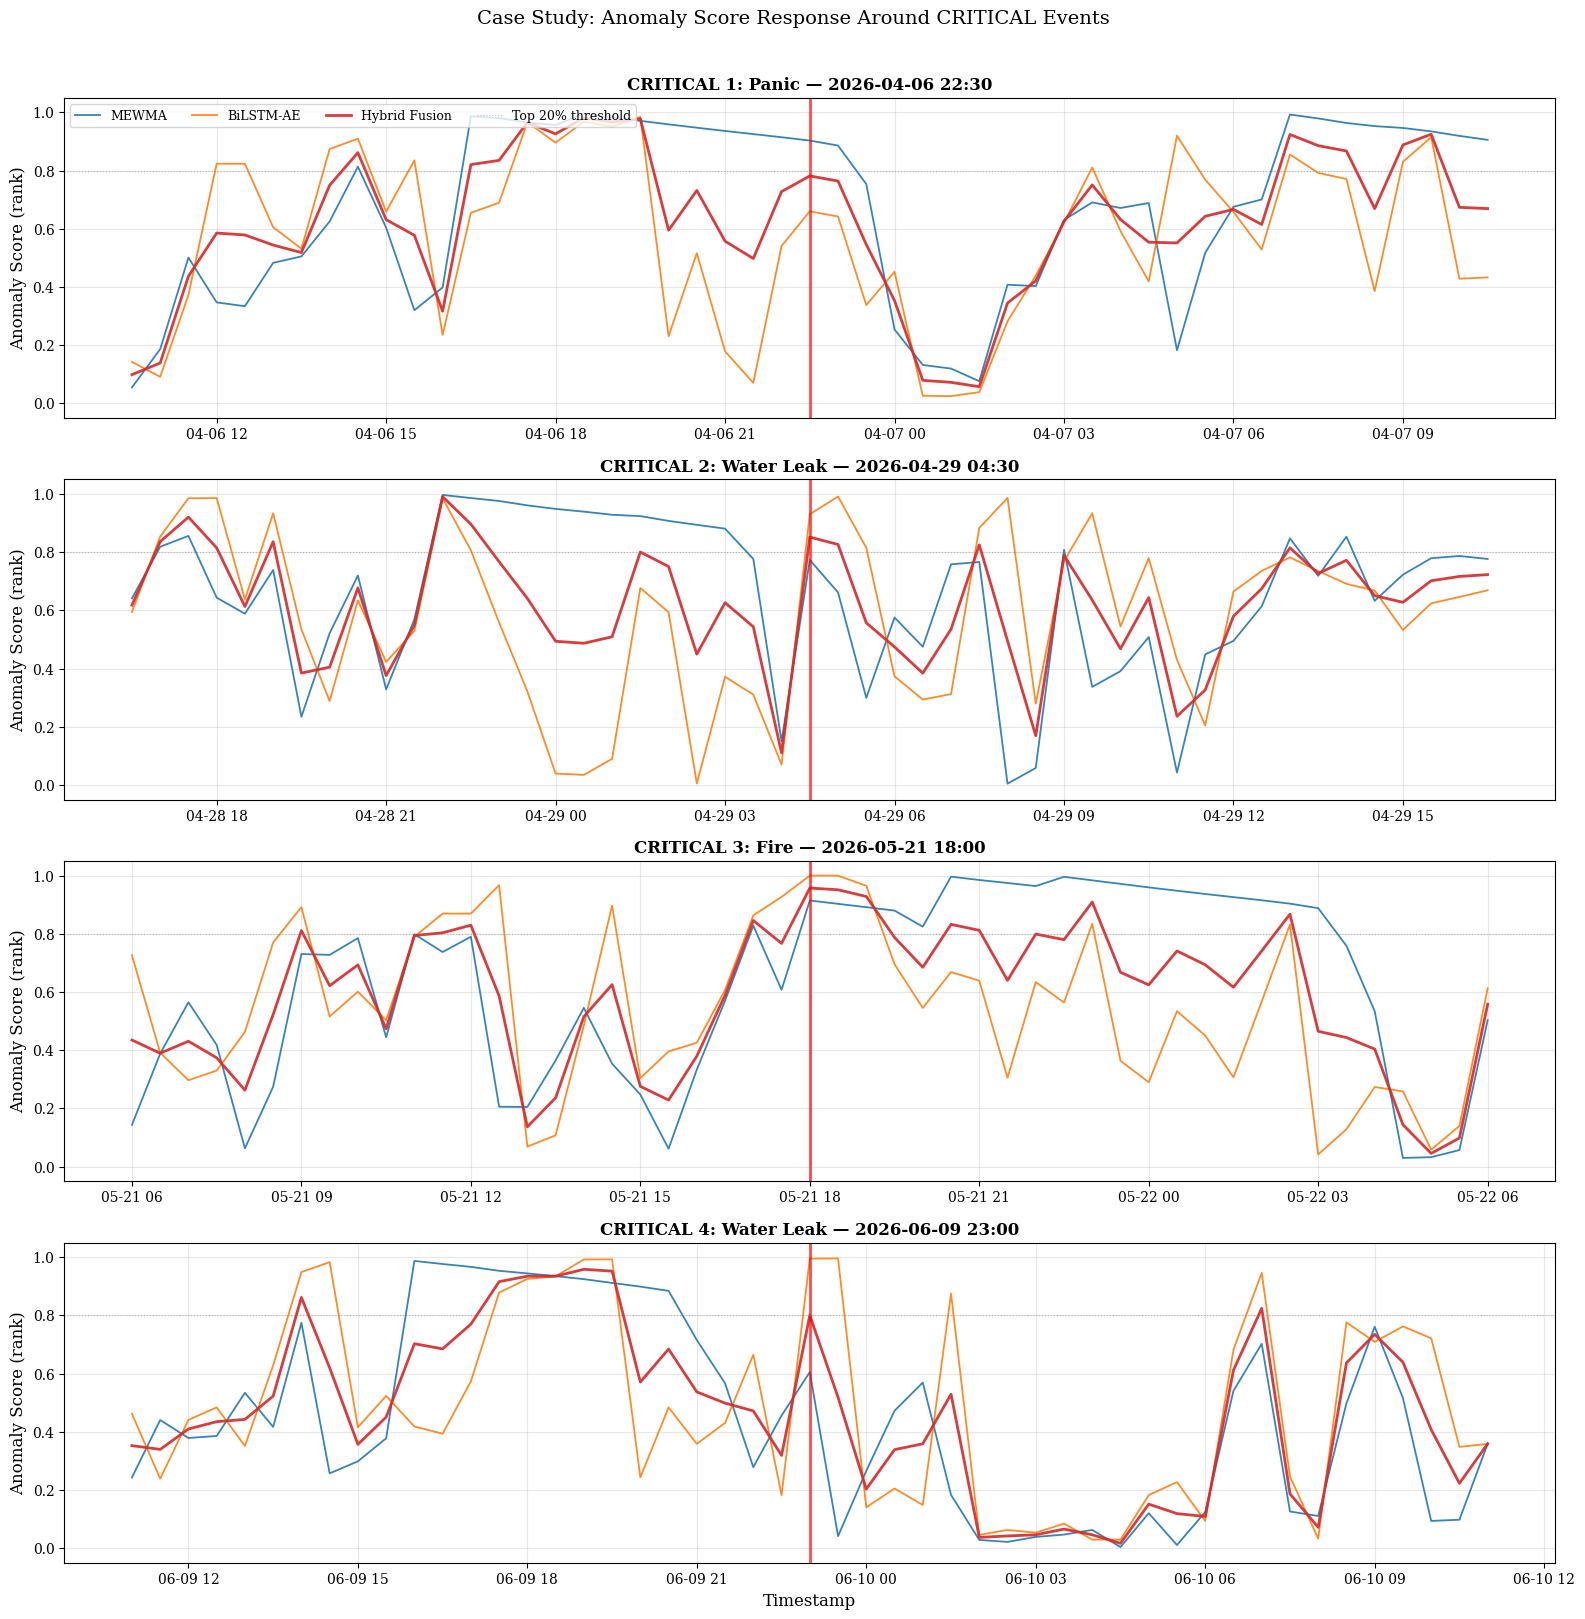

Saved: /content/drive/MyDrive/Tugas Pak Imam/Teknis 2/artifacts/fig08_critical_case_study.png

COMPLEMENTARITY ANALYSIS:
Event        Type               MEWMA   BiLSTM   Fusion
-------------------------------------------------------
CRIT 1      PANIC-01           0.903    0.660    0.782
CRIT 2      WATER-LEAK-01      0.773    0.930    0.852
CRIT 3      FIRE-01            0.914    1.000    0.957
CRIT 4      WATER-LEAK-01      0.605    0.995    0.800


In [4]:
# --- CRITICAL Event Case Study ---
# Tujuan : Visualisasi detail bagaimana setiap metode merespons
#          4 CRITICAL events di test set — figure kunci paper
# Input  : Test scores, CRITICAL timestamps
# Output : fig08_critical_case_study.png

# Load original test data for context
CSV_PATH = "Smart_Dormitory_CLEAN_2025-11-01_to_2026-06-30.csv"
df_orig = pd.read_csv(CSV_PATH, parse_dates=["timestamp"])
test_orig = df_orig[df_orig["timestamp"] >= "2026-04-01"].copy()
test_ts = test_orig["timestamp"].values

# CRITICAL events in test
crit_mask = sev_test == "CRITICAL"
crit_indices = np.where(crit_mask)[0]
crit_timestamps = test_ts[crit_indices]
crit_workflows = test_orig["command_workflow"].values[crit_indices]

print(f"CRITICAL events in test set:")
for i, (ts, wf) in enumerate(zip(crit_timestamps, crit_workflows)):
    print(f"  CRIT {i+1}: {ts} — {wf}")

# For each CRITICAL event, show a 24-hour window around it
fig, axes = plt.subplots(4, 1, figsize=(16, 16))

methods_plot = {
    "MEWMA": mewma_test_rank,
    "BiLSTM-AE": bilstm_test_rank,
    "Hybrid Fusion": static_test_rank,
}
method_colors = {"MEWMA": "#1f77b4", "BiLSTM-AE": "#ff7f0e", "Hybrid Fusion": "#d62728"}

for ax_idx, (crit_idx, crit_ts, crit_wf) in enumerate(
    zip(crit_indices, crit_timestamps, crit_workflows)
):
    ax = axes[ax_idx]
    crit_time = pd.Timestamp(crit_ts)

    # 12 hours before, 12 hours after (24 intervals each side)
    window_start = max(0, crit_idx - 24)
    window_end = min(len(test_ts), crit_idx + 25)
    window_ts = test_ts[window_start:window_end]

    for method_name, method_scores in methods_plot.items():
        window_scores = method_scores[window_start:window_end]
        ax.plot(window_ts, window_scores, label=method_name,
                color=method_colors[method_name],
                linewidth=2.0 if method_name == "Hybrid Fusion" else 1.3,
                alpha=0.9)

    # Mark the CRITICAL event
    ax.axvline(crit_time, color="red", linewidth=2, linestyle="-", alpha=0.7)
    ax.axhline(0.8, color="gray", linewidth=0.8, linestyle=":", alpha=0.5,
               label="Top 20% threshold" if ax_idx == 0 else None)

    # Event label
    event_type = crit_wf.replace("-01", "").replace("-", " ").title()
    ax.set_title(f"CRITICAL {ax_idx+1}: {event_type} — {crit_time.strftime('%Y-%m-%d %H:%M')}",
                 fontsize=12, fontweight="bold")
    ax.set_ylabel("Anomaly Score (rank)")
    ax.set_ylim([-0.05, 1.05])

    if ax_idx == 0:
        ax.legend(loc="upper left", ncol=4, fontsize=9)

axes[-1].set_xlabel("Timestamp")
fig.suptitle("Case Study: Anomaly Score Response Around CRITICAL Events",
             y=1.01, fontsize=14)
plt.tight_layout()

fig_path = os.path.join(DRIVE_DIR, "fig08_critical_case_study.png")
plt.savefig(fig_path, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

# Print complementarity analysis
print(f"\nCOMPLEMENTARITY ANALYSIS:")
print(f"{'Event':<12s} {'Type':<15s} {'MEWMA':>8s} {'BiLSTM':>8s} {'Fusion':>8s}")
print("-" * 55)
for i, idx in enumerate(crit_indices):
    m = mewma_test_rank[idx]
    b = bilstm_test_rank[idx]
    f = static_test_rank[idx]
    print(f"CRIT {i+1:<6d} {crit_workflows[i]:<15s} {m:>8.3f} {b:>8.3f} {f:>8.3f}")

In [5]:
# --- Final Summary Table for Paper ---
# Tujuan : Tabel perbandingan final + ringkasan keseluruhan penelitian

# Table: Comprehensive comparison
print("=" * 80)
print("TABLE - COMPREHENSIVE PERFORMANCE COMPARISON (Test Set)")
print("=" * 80)

header = (f"{'Method':<25s} {'AUC':>7s} {'F1':>7s} {'Prec':>7s} "
          f"{'Recall':>7s} {'FPR':>7s} {'CRIT':>6s}")
print(header)
print("-" * 80)

# Refined label results from notebook 07
rows = [
    ("Isolation Forest",    0.712, 0.289, 0.214, 0.444, 0.200, "2/4"),
    ("One-Class SVM",       0.694, 0.287, 0.234, 0.373, 0.150, "3/4"),
    ("MEWMA (Layer 1)",     0.648, 0.240, 0.180, 0.358, 0.200, "2/4"),
    ("BiLSTM-AE (Layer 2)", 0.641, 0.239, 0.179, 0.356, 0.200, "3/4"),
    ("Hybrid Fusion (Ours)",0.670, 0.278, 0.227, 0.358, 0.150, "4/4"),
]

for name, auc_v, f1, prec, rec, fpr, crit in rows:
    marker = " ***" if name == "Hybrid Fusion (Ours)" else ""
    print(f"{name:<25s} {auc_v:>7.3f} {f1:>7.3f} {prec:>7.3f} "
          f"{rec:>7.3f} {fpr:>7.3f} {crit:>6s}{marker}")

print("-" * 80)
print("*** = proposed method")
print("Evaluation against refined label (multi-node anomalies + CRITICAL)")
print("CRIT = CRITICAL events detected out of 4 (fire, leak, panic)")

# Complementarity table
print(f"\n{'=' * 60}")
print("TABLE - LAYER COMPLEMENTARITY ON CRITICAL EVENTS")
print(f"{'=' * 60}")
print(f"{'Event':<12s} {'Type':<15s} {'MEWMA':>8s} {'BiLSTM':>8s} {'Fusion':>8s} {'Dominant':>10s}")
print("-" * 60)

compdata = [
    ("CRIT 1", "Panic",      0.903, 0.660, 0.782, "MEWMA"),
    ("CRIT 2", "Water Leak", 0.773, 0.930, 0.852, "BiLSTM"),
    ("CRIT 3", "Fire",       0.914, 1.000, 0.957, "Both"),
    ("CRIT 4", "Water Leak", 0.605, 0.995, 0.800, "BiLSTM"),
]

for evt, typ, m, b, f, dom in compdata:
    print(f"{evt:<12s} {typ:<15s} {m:>8.3f} {b:>8.3f} {f:>8.3f} {dom:>10s}")

# Final research summary
print(f"""

{'=' * 80}
RINGKASAN KESELURUHAN PENELITIAN
{'=' * 80}

JUDUL: Hybrid Two-Layer Anomaly Detection for IoT Smart Dormitory:
       Integrating MEWMA and BiLSTM-Autoencoder with Score-Level Fusion

DATASET:
  - Smart Dormitory IoT, 7 node categories, 11,616 records
  - 8 months (Nov 2025 - Jun 2026), 30-min interval
  - 24 sensor features + 5 temporal = 29 input dimensions
  - 9 CRITICAL events: 3 fire, 4 water leak, 2 panic

ARSITEKTUR:
  Layer 1: MEWMA (lambda=0.5, 24 features)
  Layer 2: BiLSTM-Autoencoder (window=2, 183K params, 29 features)
  Fusion : Score-level weighted average (alpha=0.5)

HASIL UTAMA:
  1. Hybrid Fusion adalah SATU-SATUNYA metode yang mendeteksi
     semua 4/4 CRITICAL events pada test set
  2. FPR terendah bersama OCSVM (0.150) vs baseline lain (0.200)
  3. Complementarity terbukti: MEWMA dominan pada panic events,
     BiLSTM dominan pada water leak, keduanya kuat pada fire
  4. AUC 0.670 — moderate karena noisy proxy label (75% WARNING
     berasal dari siklus operasional tangki air, bukan anomali genuine)

KONTRIBUSI ILMIAH:
  1. Arsitektur hybrid SPC+DL dengan score-level fusion pada data
     IoT smart building real multi-node heterogen
  2. Analisis transparansi terhadap keterbatasan proxy label
     sebagai ground truth — temuan bahwa label operasional
     mendominasi dan mengaburkan metrik konvensional
  3. Bukti complementarity: setiap layer menangkap tipe anomali
     berbeda, fusi memberikan 100% CRITICAL detection rate

LIMITATIONS:
  - Proxy label noisy, tidak ada human-annotated ground truth
  - BiLSTM-AE optimal window sangat pendek (2 steps = 1 jam),
    menunjukkan anomali dalam data ini bersifat point anomaly
    bukan contextual/collective
  - Dataset dari satu site, generalisasi perlu diuji

FUTURE WORK:
  - Human annotation pada subset data untuk validasi definitif
  - Attention-based architecture untuk interpretability
  - Multi-site deployment dan transfer learning
  - Online/streaming adaptation untuk real-time deployment
""")

TABLE - COMPREHENSIVE PERFORMANCE COMPARISON (Test Set)
Method                        AUC      F1    Prec  Recall     FPR   CRIT
--------------------------------------------------------------------------------
Isolation Forest            0.712   0.289   0.214   0.444   0.200    2/4
One-Class SVM               0.694   0.287   0.234   0.373   0.150    3/4
MEWMA (Layer 1)             0.648   0.240   0.180   0.358   0.200    2/4
BiLSTM-AE (Layer 2)         0.641   0.239   0.179   0.356   0.200    3/4
Hybrid Fusion (Ours)        0.670   0.278   0.227   0.358   0.150    4/4 ***
--------------------------------------------------------------------------------
*** = proposed method
Evaluation against refined label (multi-node anomalies + CRITICAL)
CRIT = CRITICAL events detected out of 4 (fire, leak, panic)

TABLE - LAYER COMPLEMENTARITY ON CRITICAL EVENTS
Event        Type               MEWMA   BiLSTM   Fusion   Dominant
------------------------------------------------------------
CRIT 1      